# 06 · Random Forest

The bagged ensemble: CART trees with bootstrap samples and random feature subspaces. Number of trees, depth, split and leaf sizes and `max_features` are tuned.

**Protocol (identical for every model; `src/controlled_framework.py`, `config.yaml`):**
- **Novelty-aware tuning.** Optuna TPE, the same number of trials for every model. The objective is the mean ROC-AUC over 5 *leave-attack-types-out* folds of `KDDTrain+`: each fold holds out a group of training attack types plus 1/5 of the normal rows, so the score measures how well held-out attack types are separated from normal traffic. The preprocessor is refit inside every fold.
- **Fixed parameters.** `class_weight=None` (or its equivalent) for every model; `random_state` = the run's seed.
- **Final refit.** On all of `KDDTrain+` with the **full** best-trial parameter set (tuned + fixed); `cf.check_final_params` asserts it.
- **Single evaluation on `KDDTest+`**, reported four ways:
  - at the fixed threshold 0.5;
  - threshold-free (ROC-AUC, PR-AUC, AUC of seen attacks vs normals, AUC of unseen attacks vs normals);
  - at FPR budgets of 1/2/5% read off the test ROC curve (ranking quality at a matched FPR);
  - at *deployable* thresholds, chosen so that 1/2/5% of the out-of-fold `KDDTrain+` normals exceed them. These use training data only, so the realised test FPR can differ from the budget.
- **Seeds.** The whole pipeline (tuning + refit + evaluation) runs once per seed in `config.yaml`. The primary seed (42) writes the model and the headline files; the other seeds write to `results/*/seeds/`.

**Outputs:** `models/random_forest.joblib`, `results/metrics/random_forest.json`, `results/predictions/random_forest_predictions.csv`, `results/predictions/random_forest_oof_train_scores.csv`, `results/tuning/random_forest_trials.{json,csv}`, `results/*/seeds/random_forest_seed*.*`, `results/tables/random_forest_*.{csv,md}`, `results/figures/random_forest/*.png`.

In [1]:
import sys, json, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src.config import set_all_seeds
from src import controlled_framework as cf

rng = set_all_seeds(cf.SEED)
sns.set_theme(style="whitegrid", context="notebook")
print(f"primary seed={cf.SEED} | seeds={cf.SEEDS} | trials={cf.N_TRIALS} | novelty CV folds={cf.N_SPLITS} | "
      f"threshold={cf.THRESHOLD} | FPR budgets={cf.FPR_BUDGETS} | class_weight={cf.CLASS_WEIGHT}")

primary seed=42 | seeds=[42, 1, 2, 3, 4] | trials=25 | novelty CV folds=5 | threshold=0.5 | FPR budgets=[0.01, 0.02, 0.05] | class_weight=None


## 1. Search space and fixed parameters

In [2]:
MODEL_NAME = "Random Forest"
FIXED = {"class_weight": cf.CLASS_WEIGHT, "bootstrap": True, "n_jobs": -1, "random_state": cf.SEED}
FOLD_JOBS = 1   # CV folds run in parallel for single-threaded estimators

def suggest(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 50, 150, step=25),
        "max_depth": trial.suggest_categorical("max_depth", [None, 5, 10, 15, 20, 25]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20, log=True),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"]),
    }

from sklearn.ensemble import RandomForestClassifier

def factory(params):
    return RandomForestClassifier(**params)

def complexity(pipe, preds):
    clf = pipe.named_steps["clf"]
    depths = [e.get_depth() for e in clf.estimators_]; leaves = [e.get_n_leaves() for e in clf.estimators_]
    return {"n_trees": len(clf.estimators_), "mean_depth": float(np.mean(depths)), "max_depth": int(np.max(depths)),
            "mean_leaves": float(np.mean(leaves)), "total_leaves": int(np.sum(leaves))}

print("fixed:", FIXED)

fixed: {'class_weight': None, 'bootstrap': True, 'n_jobs': -1, 'random_state': 42}


## 2. Primary seed: tune (novelty CV), refit on `KDDTrain+`, evaluate once on `KDDTest+`

In [3]:
data = cf.load_dataset()
res = cf.run_controlled_experiment(MODEL_NAME, suggest, factory, FIXED, seed=cf.SEED, data=data, fold_jobs=FOLD_JOBS)
res.metrics["model_complexity"] = complexity(res.pipeline, res.predictions)
print()
print("best novelty CV AUC:", round(res.best_cv_auc, 4), "| fold AUCs:", np.round(res.best_cv_fold_aucs, 4))
print("final model parameters:", res.best_params)
print("model complexity:", res.metrics["model_complexity"])

  [Random Forest | seed 42] trial 01/25  novelty CV AUC 0.9880 (±0.0101)


  [Random Forest | seed 42] trial 02/25  novelty CV AUC 0.9927 (±0.0072)


  [Random Forest | seed 42] trial 03/25  novelty CV AUC 0.9784 (±0.0174)


  [Random Forest | seed 42] trial 04/25  novelty CV AUC 0.9845 (±0.0139)


  [Random Forest | seed 42] trial 05/25  novelty CV AUC 0.9787 (±0.0199)


  [Random Forest | seed 42] trial 06/25  novelty CV AUC 0.9858 (±0.0115)


... (16 outputs left out)

  [Random Forest | seed 42] trial 23/25  novelty CV AUC 0.9942 (±0.0045)


  [Random Forest | seed 42] trial 24/25  novelty CV AUC 0.9935 (±0.0051)


  [Random Forest | seed 42] trial 25/25  novelty CV AUC 0.9876 (±0.0103)



best novelty CV AUC: 0.9942 | fold AUCs: [0.9992 0.9925 0.9996 0.9884 0.9911]
final model parameters: {'class_weight': None, 'bootstrap': True, 'n_jobs': -1, 'random_state': 42, 'n_estimators': 150, 'max_depth': 20, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
model complexity: {'n_trees': 150, 'mean_depth': 20.0, 'max_depth': 20, 'mean_leaves': 455.74666666666667, 'total_leaves': 68362}


## 3. Tuning results

The cell also reports how far apart the best trials are relative to the fold-to-fold standard deviation. A spread smaller than one fold SD means this objective does not clearly separate the top configurations.

top-5 spread = 0.00172  vs  best-trial fold SD = 0.00449


,trial,mean_auc,std_auc,duration_seconds,class_weight,bootstrap,n_jobs,random_state,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features
0,22,0.994155,0.004490,14.68,None,True,-1,42,150,20.0,5,1,sqrt
1,23,0.993470,0.005052,11.34,None,True,-1,42,100,20.0,4,1,sqrt
2,15,0.993086,0.005446,21.82,None,True,-1,42,150,20.0,5,2,sqrt
3,1,0.992716,0.007219,24.05,None,True,-1,42,150,NaN,5,1,sqrt
4,11,0.992435,0.007113,21.87,None,True,-1,42,150,25.0,5,1,sqrt
5,16,0.992362,0.006025,18.20,None,True,-1,42,125,20.0,5,2,sqrt
6,13,0.991100,0.008082,19.80,None,True,-1,42,125,25.0,4,1,sqrt
7,8,0.990868,0.007238,22.40,None,True,-1,42,150,25.0,6,3,sqrt
8,20,0.990750,0.008699,11.50,None,True,-1,42,150,NaN,7,1,log2
9,14,0.990271,0.008149,19.23,None,True,-1,42,125,NaN,3,2,sqrt


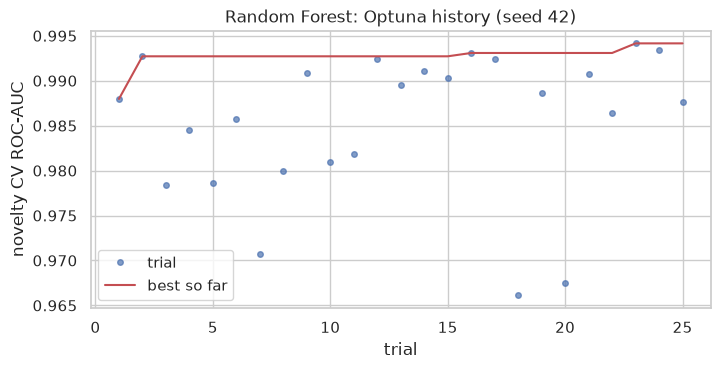

In [4]:
tt = cf.trials_table(res)
spread = tt["mean_auc"].iloc[0] - tt["mean_auc"].iloc[min(4, len(tt) - 1)]
print(f"top-5 spread = {spread:.5f}  vs  best-trial fold SD = {np.std(res.best_cv_fold_aucs):.5f}")
display(tt.head(10))

fig, ax = plt.subplots(figsize=(8, 3.6))
vals = [t["mean_auc"] for t in res.trials]
ax.plot(range(1, len(vals) + 1), vals, "o", ms=4, alpha=.7, label="trial")
ax.plot(range(1, len(vals) + 1), np.maximum.accumulate(vals), "-", color="#C44E52", label="best so far")
ax.set_xlabel("trial"); ax.set_ylabel("novelty CV ROC-AUC"); ax.set_title(f"{MODEL_NAME}: Optuna history (seed {cf.SEED})"); ax.legend()
cf.save_figure(fig, "random_forest", "tuning_history"); plt.show()

## 4. Test results (`KDDTest+`)

In [5]:
m = res.metrics
display(pd.Series(cf.summary_row(m)).to_frame(MODEL_NAME))
ops = pd.concat({"test ROC reading (matched test FPR)": pd.DataFrame(m["test_roc_operating_points"]).T,
                 "deployable (OOF-calibrated threshold)": pd.DataFrame(m["deployable_operating_points"]).T}).reset_index(names=["kind", "budget"])
cat = pd.DataFrame(m["attack_category_recall"]).T.reset_index(names="category")
strat = pd.DataFrame([{"category": c, "seen_n": v["seen"]["total_samples"], "seen_recall": v["seen"]["recall"],
                       "unseen_n": v["unseen"]["total_samples"], "unseen_recall": v["unseen"]["recall"]}
                      for c, v in m["category_stratified_seen_unseen_recall"].items()])
unseen = pd.DataFrame(m["per_unseen_attack_recall"]).T.reset_index(names="attack").sort_values("total_samples", ascending=False)
cf.save_table(ops, "random_forest_operating_points")
cf.save_table(cat, "random_forest_category_recall")
cf.save_table(strat, "random_forest_category_stratified")
cf.save_table(unseen, "random_forest_per_unseen_attack")
display(ops); display(strat); display(unseen)

,Random Forest
model,Random Forest
accuracy,0.769374
macro_f1,0.768281
attack_precision,0.967655
attack_recall,0.615445
false_positive_rate,0.027188
seen_recall,0.7679
unseen_recall,0.2461
generalization_drop_pp,52.18
reweighted_drop_pp,57.35


,kind,budget,threshold,fpr,attack_recall,seen_recall,unseen_recall
0,test ROC reading (matched test FPR),fpr_1pct,0.980000,0.009269,0.462869,0.624353,0.071733
1,test ROC reading (matched test FPR),fpr_2pct,0.922857,0.019979,0.515078,0.689310,0.093067
2,test ROC reading (matched test FPR),fpr_5pct,0.212784,0.043048,0.761474,0.814379,0.633333
3,deployable (OOF-calibrated threshold),fpr_1pct,0.080359,0.098970,0.890984,0.896070,0.878667
4,deployable (OOF-calibrated threshold),fpr_2pct,0.040006,0.112461,0.941947,0.948805,0.925333
5,deployable (OOF-calibrated threshold),fpr_5pct,0.013456,0.134809,0.980831,0.991302,0.955467


,category,seen_n,seen_recall,unseen_n,unseen_recall
0,DoS,5741,0.9969,1717,0.1165
1,Probe,1106,1.0000,1315,0.5422
2,R2L,2199,0.0655,688,0.0073
3,U2R,37,0.0541,30,0.1667


,attack,category,total_samples,detected,missed,recall
3,mscan,Probe,996,398,598,0.3996
0,apache2,DoS,737,193,544,0.2619
5,processtable,DoS,685,5,680,0.0073
10,snmpguess,R2L,331,0,331,0.0
7,saint,Probe,319,315,4,0.9875
2,mailbomb,DoS,293,0,293,0.0
9,snmpgetattack,R2L,178,0,178,0.0
1,httptunnel,R2L,133,2,131,0.015
4,named,R2L,17,2,15,0.1176
6,ps,U2R,15,2,13,0.1333


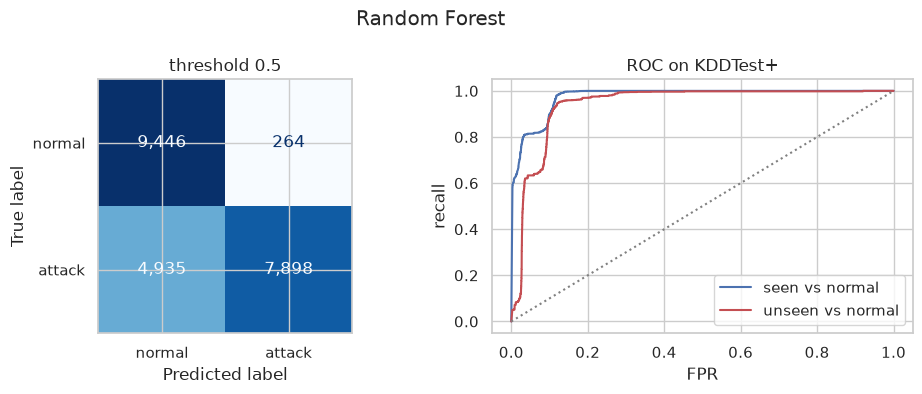

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(np.array(m["overall_metrics"]["confusion_matrix"]), display_labels=["normal", "attack"]).plot(
    ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title("threshold 0.5")
p = res.predictions
for name, mask, col in [("seen vs normal", (p.y_true == 0) | ~p.is_unseen, "#4C72B0"), ("unseen vs normal", (p.y_true == 0) | p.is_unseen, "#C44E52")]:
    fpr, tpr, _ = roc_curve(p.y_true[mask], p.y_prob[mask]); axes[1].plot(fpr, tpr, color=col, label=name)
axes[1].plot([0, 1], [0, 1], ":", color="grey"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("recall"); axes[1].legend()
axes[1].set_title("ROC on KDDTest+")
fig.suptitle(MODEL_NAME); fig.tight_layout()
cf.save_figure(fig, "random_forest", "confusion_and_roc"); plt.show()

## 5. Save primary-seed artifacts

In [7]:
paths = cf.save_experiment(res, primary=True)
for k, v in paths.items():
    print(f"{k:12s} {v.relative_to(PROJECT_ROOT)}")

metrics      results/metrics/random_forest.json
predictions  results/predictions/random_forest_predictions.csv
tuning_json  results/tuning/random_forest_trials.json
tuning_csv   results/tuning/random_forest_trials.csv
model        models/random_forest.joblib
oof          results/predictions/random_forest_oof_train_scores.csv


## 6. Remaining seeds (full pipeline per seed)

In [8]:
seed_rows = [cf.summary_row(res.metrics) | {"seed": cf.SEED, "best_novelty_cv_auc": res.best_cv_auc}]
for s in [s for s in cf.SEEDS if s != cf.SEED]:
    r = cf.run_controlled_experiment(MODEL_NAME, suggest, factory, FIXED, seed=s, data=data, fold_jobs=FOLD_JOBS, verbose=False)
    r.metrics["model_complexity"] = complexity(r.pipeline, r.predictions)
    cf.save_experiment(r, primary=False)
    seed_rows.append(cf.summary_row(r.metrics) | {"seed": s, "best_novelty_cv_auc": r.best_cv_auc})
    print(f"seed {s}: CV AUC {r.best_cv_auc:.4f} | test unseen AUC {r.metrics['threshold_free']['roc_auc_unseen_vs_normal']:.4f} | "
          f"unseen recall@0.5 {r.metrics['seen_vs_unseen_recall']['unseen_recall']:.4f} | params { {k: v for k, v in r.best_params.items() if k not in FIXED} }")
    del r
seeds_tbl = pd.DataFrame(seed_rows)
cols = ["seed", "best_novelty_cv_auc", "macro_f1", "false_positive_rate", "seen_recall", "unseen_recall",
        "auc_seen_vs_normal", "auc_unseen_vs_normal", "unseen_recall@test_fpr_2pct", "test_fpr@oof_fpr_2pct", "unseen_recall@oof_fpr_2pct"]
seeds_tbl = seeds_tbl[cols]
cf.save_table(seeds_tbl, "random_forest_seeds")
display(seeds_tbl)
display(seeds_tbl.drop(columns="seed").agg(["mean", "std"]).T)

seed 1: CV AUC 0.9910 | test unseen AUC 0.9393 | unseen recall@0.5 0.2365 | params {'n_estimators': 50, 'max_depth': None, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt'}


seed 2: CV AUC 0.9937 | test unseen AUC 0.9402 | unseen recall@0.5 0.2453 | params {'n_estimators': 150, 'max_depth': 20, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_features': 'sqrt'}


seed 3: CV AUC 0.9902 | test unseen AUC 0.9469 | unseen recall@0.5 0.2560 | params {'n_estimators': 125, 'max_depth': None, 'min_samples_split': 8, 'min_samples_leaf': 2, 'max_features': 'sqrt'}


seed 4: CV AUC 0.9941 | test unseen AUC 0.9370 | unseen recall@0.5 0.2637 | params {'n_estimators': 100, 'max_depth': 20, 'min_samples_split': 8, 'min_samples_leaf': 1, 'max_features': 'sqrt'}


,seed,best_novelty_cv_auc,macro_f1,false_positive_rate,seen_recall,unseen_recall,auc_seen_vs_normal,auc_unseen_vs_normal,unseen_recall@test_fpr_2pct,test_fpr@oof_fpr_2pct,unseen_recall@oof_fpr_2pct
0,42,0.994155,0.768281,0.027188,0.7679,0.2461,0.975175,0.941684,0.093067,0.112461,0.925333
1,1,0.991005,0.767074,0.026777,0.7686,0.2365,0.973956,0.939330,0.087467,0.105458,0.871733
2,2,0.993725,0.768460,0.026982,0.7685,0.2453,0.975419,0.940202,0.089600,0.117096,0.916267
3,3,0.990230,0.769230,0.026571,0.7655,0.2560,0.974976,0.946894,0.058667,0.104840,0.876533
4,4,0.994125,0.772115,0.026262,0.7689,0.2637,0.973772,0.937000,0.090400,0.109475,0.928533


,mean,std
best_novelty_cv_auc,0.992648,0.001882
macro_f1,0.769032,0.001889
false_positive_rate,0.026756,0.000359
seen_recall,0.767880,0.001379
unseen_recall,0.249520,0.010513
auc_seen_vs_normal,0.974660,0.000746
auc_unseen_vs_normal,0.941022,0.003696
unseen_recall@test_fpr_2pct,0.083840,0.014214
test_fpr@oof_fpr_2pct,0.109866,0.005095
unseen_recall@oof_fpr_2pct,0.903680,0.027398


**Reading these numbers.** Seed-to-seed spread shows how much of any difference between models comes from training and tuning randomness rather than from the model family. The cross-model comparison is in `08_evaluation_comparison.ipynb`.